# TP 1 : Prétraitement d’un Dataset en Machine Learning

**Réalisé par :** YOUNES AIT ESSAHEL <br>
**Filière :** Masster IAA_S1 <br>
**Module :** Apprentissage automatique <br>
**Lien GitHub :** https://github.com/Younes-Ait-Essahel2520/TPs_Apprentissage-automatique.git <br>
**Année universitaire :** 2025-2026



## Partie 1 : Introduction au Dataset

### Etape 1 : charger  dataset 

In [55]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE


In [2]:
df = pd.read_csv("Titanic-Dataset.csv")

### Etape 2 : Analyser le dataset 

#### Identifier le types de donnees 

In [3]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

#### Visualiser les 5 premieres lignes 

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### verfier les valeur monquantes 

In [5]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## Partie 2 : Nettoyage des Données

### 1. Gestion des valeurs manquantes :

#### calcule % des valeurs monquantres pour chaque colonne 
l'objectif choisir la methode de trainement la puls adaptee 

In [6]:
(df.isnull().sum() / len(df)) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

#### Etape 1 : supprimer la colonne Cabin 
par ce que la % des valeur monquantes(Cabin) = 77% > 40% (TP1)

In [7]:
df.drop(columns=['Cabin'], inplace=True)

#### Etape 2 : Traiter les valeurs manquqntes de AGE aves le Mediane 
par ce que mediane est moins sensible aux valeurs manqantes par apport a le moyenne  

In [8]:
df['Age'] = df['Age'].fillna(df['Age'].median() )

verfication les valeurs manquantes de l'age :

In [9]:
 df['Age'].isnull().sum()

np.int64(0)

#### Etape 3 : traiter le Embarked avec le mode 
par ce que ce colonne est un Categoriel , 
determier la valeurs la plus repeter 

In [10]:
df['Embarked'].mode()

0    S
Name: Embarked, dtype: object

 Alors en rempalce les valeurs manquantes par la valeur la plus repeter : s

In [11]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

#### Verfier touts les valeurs manqantes 

In [12]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

### 2. Gestion des valeurs aberrantes :

#### Etape 1 : Identifier les valeurs numeriques 
pour determiner les colonnes numerique pour appliquer Boxplots (valeurs aberrantes)

In [13]:
df.select_dtypes(include=['int64', 'float64']).columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

#### Etape 2 : Visualiser les valeurs anerrantes avec un Boxplot 
Exemple : en choisier l'Age par ce que est un varaible numerique continue ,  infliences dans les donnees

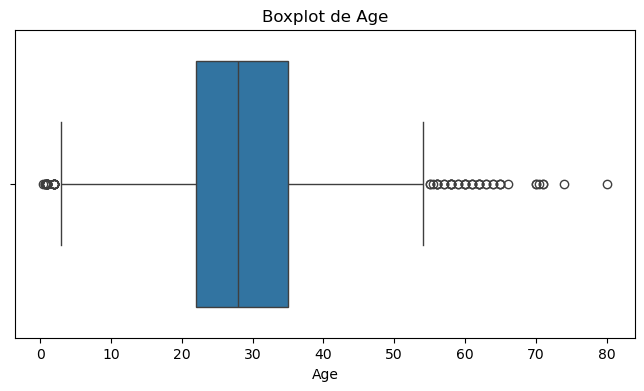

In [14]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Age'])
plt.title('Boxplot de Age' )
plt.show()

Remarque :
puisque les valeurs abereantes entre 55 < Age < 80 , est  ca possible alors : valeurs aberrantes potentielles .
Q1=22 et Q3=35 mediane=28 

#### methode IQR

In [15]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1)
print("Q =", Q3)
print("IQR =", IQR)

Q1 = 22.0
Q = 35.0
IQR = 13.0


#### calcule les bornes [L,U]

In [16]:
L = Q1 - 1.5 * IQR
U = Q1 + 1.5 * IQR
print(f"[L,U] = [{L},{U}]")

[L,U] = [2.5,41.5]


#### clalcule le nombres des valeurs aberrantes 

In [17]:
aberrantes = df[(df['Age'] < L) | (df['Age'] > U)]
print(f"monbres des valeurs aberrantes est {len(aberrantes)}")

monbres des valeurs aberrantes est 166


In [18]:
df.shape # taille de tableu / 18.63% valeurs aberrantes

(891, 11)

#### remplacer les valeurs aberrantes par le medaine 
valeurs aberrantes potentielles 166 + TP

In [19]:
median_Age = df['Age'].median()
print(f"Medaine de l'Age = {median_Age}")

Medaine de l'Age = 28.0


In [20]:
Abrr = (df['Age'] < L) | (df['Age'] > U)
df.loc[Abrr, 'Age'] = median_Age
print(Abrr.sum())

166


In [21]:
print(f"Nombres de valeurs egales a  la mediane :{(df['Age'] == median_Age).sum()}")

Nombres de valeurs egales a  la mediane :368


#### Verfication de Bosplot 

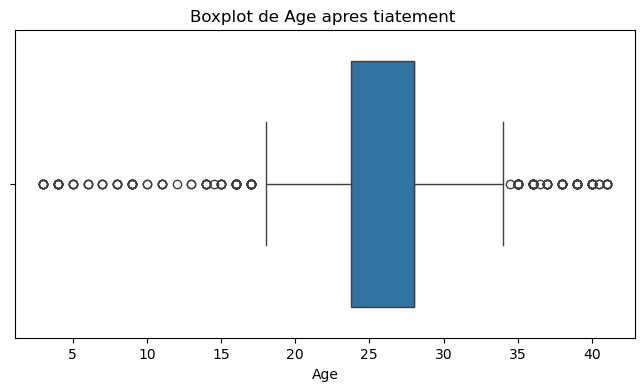

In [22]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Age'])
plt.title('Boxplot de Age apres tiatement ' )
plt.show()

#### appliquer Boxplot sur Fare

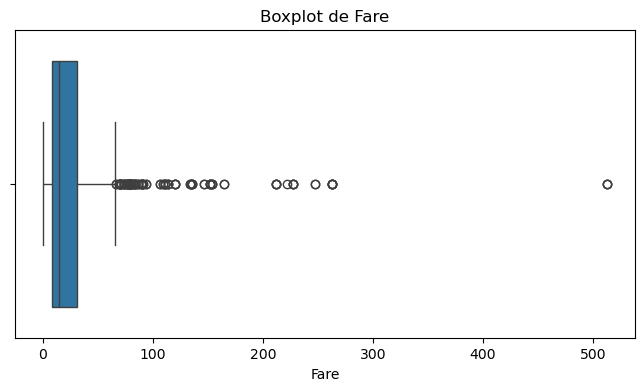

In [23]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Fare'])
plt.title('Boxplot de Fare' )
plt.show()

In [24]:
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1)
print("Q =", Q3)
print("IQR =", IQR)
L = Q1 - 1.5 * IQR
U = Q1 + 1.5 * IQR
print(f"[L,U] = [{L},{U}]")

Q1 = 7.9104
Q = 31.0
IQR = 23.0896
[L,U] = [-26.724,42.5448]


In [25]:
aberrantes = df[(df['Fare'] < L) | (df['Fare'] > U)]
print(f"monbres des valeurs aberrantes est {len(aberrantes)}")

monbres des valeurs aberrantes est 171


In [26]:
median_Fare = df['Fare'].median()
print(f"Medaine de Fare= {median_Fare}")
Abr = (df['Fare'] < L) | (df['Fare'] > U)
df.loc[Abr, 'Fare'] = median_Fare
print(Abr.sum())

Medaine de Fare= 14.4542
171


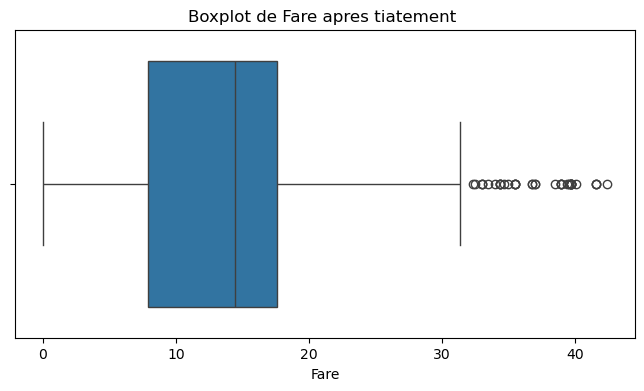

In [27]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Fare'])
plt.title('Boxplot de Fare apres tiatement ' )
plt.show()

### Partie 3 : Transformation des donnees 

In [28]:
df.select_dtypes(include=['object']).columns

Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')

#### 1 _ En apppliquer Encodage des vraiables nominales

In [29]:
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [30]:
df = pd.get_dummies(df , columns =['Sex'] , dtype=int)


In [31]:
#df.head()

In [32]:
df['Embarked'].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [33]:
df = pd.get_dummies(df , columns =['Embarked'] , dtype=int)
#df.head()

In [34]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q',
       'Embarked_S'],
      dtype='object')

### 2 _ Normalisation et standarisation des donnes 

In [35]:
colonnes_numeriques = ['Pclass','Age' ,'SibSp', 'Parch' , 'Fare']

#### conserver data avant  normali...

In [36]:
df_avant = df.copy()

#### A _ Normalisation : Max-Min scaling
import MinMaxScaler()

In [37]:
s_min = MinMaxScaler()
df_normalise = df.copy()
df_normalise[colonnes_numeriques] = s_min.fit_transform(df[colonnes_numeriques])

In [38]:
df_normalise[colonnes_numeriques].head

<bound method NDFrame.head of      Pclass       Age  SibSp     Parch      Fare
0       1.0  0.500000  0.125  0.000000  0.170991
1       0.0  0.921053  0.125  0.000000  0.340901
2       1.0  0.605263  0.000  0.000000  0.186910
3       0.0  0.842105  0.125  0.000000  0.340901
4       1.0  0.842105  0.000  0.000000  0.189858
..      ...       ...    ...       ...       ...
886     0.5  0.631579  0.000  0.000000  0.306604
887     0.0  0.421053  0.000  0.000000  0.707547
888     1.0  0.657895  0.125  0.333333  0.553066
889     0.0  0.605263  0.000  0.000000  0.707547
890     1.0  0.763158  0.000  0.000000  0.182783

[891 rows x 5 columns]>

##### verfier est ce que les valeurs devine max = 1 ou bien min = 0

In [39]:
df_normalise[colonnes_numeriques].agg(['min' , 'max'])

,Pclass,Age,SibSp,Parch,Fare
min,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0


#### B _ StandardScaler (Z_score)

In [40]:
s_stand =  StandardScaler()
df_stand = df.copy()
df_stand[colonnes_numeriques] = s_stand .fit_transform(df[colonnes_numeriques])

In [41]:
df_stand[colonnes_numeriques].head

<bound method NDFrame.head of        Pclass       Age     SibSp     Parch      Fare
0    0.827377 -0.610353  0.432793 -0.473674 -0.908353
1   -1.566107  1.654403  0.432793 -0.473674 -0.057204
2    0.827377 -0.044164 -0.474545 -0.473674 -0.828604
3   -1.566107  1.229762  0.432793 -0.473674 -0.057204
4    0.827377  1.229762 -0.474545 -0.473674 -0.813836
..        ...       ...       ...       ...       ...
886 -0.369365  0.097383 -0.474545 -0.473674 -0.229012
887 -1.566107 -1.034995 -0.474545 -0.473674  1.779473
888  0.827377  0.238931  0.432793  2.008933  1.005615
889 -1.566107 -0.044164 -0.474545 -0.473674  1.779473
890  0.827377  0.805120 -0.474545 -0.473674 -0.849280

[891 rows x 5 columns]>

##### Verifier est ce que Ecart-type prouche a 1 et Moyenne prouche a 0

In [42]:
df_stand[colonnes_numeriques].agg(['mean' , 'std'])

,Pclass,Age,SibSp,Parch,Fare
mean,-8.772133e-17,-8.971499e-17,4.386066e-17,5.382900e-17,7.775299e-17
std,1.000562e+00,1.000562e+00,1.000562e+00,1.000562e+00,1.000562e+00


#### C _ Comparaison des distubutions avec des histogrammes 

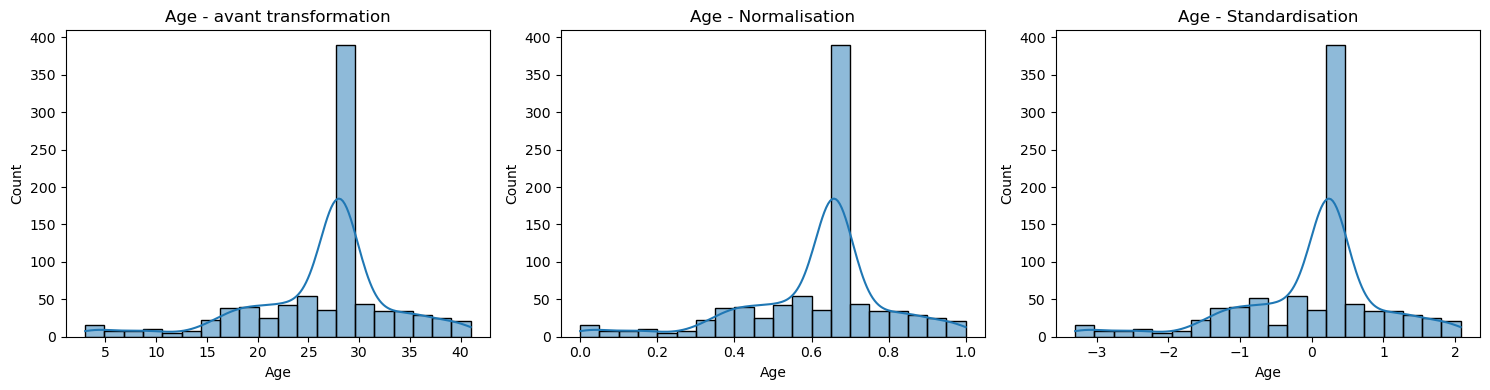

In [43]:
plt.figure(figsize=(15 ,4))

plt.subplot( 1, 3, 1)
sns.histplot(df_avant['Age'], bins = 20 , kde=True)
plt.title('Age - avant transformation')

plt.subplot( 1, 3, 2)
sns.histplot(df_normalise['Age'], bins = 20 , kde=True)
plt.title('Age - Normalisation')

plt.subplot( 1, 3, 3)
sns.histplot(df_stand['Age'], bins = 20 , kde=True)
plt.title('Age - Standardisation' )

plt.tight_layout()
plt.show()

###### Remarque : les histogrammes montrent que la Normalisation(MinMax scaling) et la Standardisation (Z-score) modifient des valeurs de la variable Age , sans changer la forme generale de sa distibution 

### Partie 4 : Gestion des donnes Desequilibrees

#### A _ Identification du  Desequilibrees des classes 
verfient data eq

In [44]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [45]:
df['Survived'].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

Desequilibre Car decedes = 61,62%   survivants = 38.38%

### B _ Gestion de desequilibre 

#### Prepaation des donnees 
module x
target y

In [49]:
x = df_stand [ 
    ['Pclass', 'Age' ,'SibSp','Parch','Fare' ]
].copy()

x[['Sex_female', 'Sex_male',
   'Embarked_C', 'Embarked_Q', 'Embarked_S']] = df[
    ['Sex_female', 'Sex_male',
     'Embarked_C', 'Embarked_Q', 'Embarked_S']
]
y = df['Survived']

In [50]:
print(x.shape)
print(y.shape)

(891, 10)
(891,)


#### Application Sous-échantillonnage (Underampling) 
import RandomUnderSampler

In [53]:
undersampler = RandomUnderSampler(random_state=42)
x_under , y_under = undersampler.fit_resample(x , y)


In [60]:
print(y_under.value_counts())  # 549 / en supprmier alaitoire 207 Echantillon pour l'eq

Survived
0    342
1    342
Name: count, dtype: int64


#### Sur-échantillonnage (oversampling) : méthode SMOTE

In [58]:
smote = SMOTE(random_state=42)
x_smote , y_smote = smote.fit_resample(x,y)

In [59]:
print(y_smote.value_counts())  # en ajoute 207 Échantillons synthétiques pou l'eq

Survived
0    549
1    549
Name: count, dtype: int64


##### les deux methodes permettent d'obtenier un dataset equilibre .L'Undersampling reduirt le nombre total d'observations , tandis que SMOTE augmente ce nombre en generant des exemples synthetiques 

In [1]:
import os
print(os.getcwd())

C:\Users\4B\TPs_Apprentissage automatique\TP_1
